# Homework 6 Fully Connected Neural Networks

Housing price regression and breast cancer classification using PyTorch FCNNs and traditional machine learning baselines.


In [2]:
# Import the libraries and make the results repeatable.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR

torch.manual_seed(42)
np.random.seed(42)

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Problem 1 Housing Price Prediction

### Dataset inspection and preprocessing


In [3]:
# Load the housing dataset from Google Drive.
file_path = "/content/drive/MyDrive/Dataset/Housing.csv"
housing = pd.read_csv(file_path)

housing.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [4]:
# Check the dataset structure, missing values, and data types.
print("Dataset shape:", housing.shape)
print("\nColumns:")
print(housing.columns.tolist())

print("\nMissing values:")
print(housing.isnull().sum())

print("\nData types:")
print(housing.dtypes)

Dataset shape: (545, 13)

Columns:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']

Missing values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Data types:
price                int64
area                 int64
bedrooms             int64
bathrooms            int64
stories              int64
mainroad            object
guestroom           object
basement            object
hotwaterheating     object
airconditioning     object
parking              int64
prefarea            object
furnishingstatus    object
dtype: object


In [5]:
# Separate housing price from all input features.
X = housing.drop("price", axis=1)
Y = housing["price"]

print("X shape:", X.shape)
print("Y shape:", Y.shape)

X shape: (545, 12)
Y shape: (545,)


### Training validation and testing split


In [6]:
# Keep 20% for testing and reserve part of training for validation.
X_train_full, X_test, Y_train_full, Y_test = train_test_split(
    X, Y, test_size=0.20, random_state=42
)

X_train, X_val, Y_train, Y_val = train_test_split(
    X_train_full, Y_train_full, test_size=0.20, random_state=42
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (348, 12)
Validation: (88, 12)
Testing: (109, 12)


In [7]:
# Separate numerical and categorical housing features.
numerical_columns = X.select_dtypes(exclude="object").columns
categorical_columns = X.select_dtypes(include="object").columns

print("Numerical columns:", numerical_columns.tolist())
print("Categorical columns:", categorical_columns.tolist())

Numerical columns: ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
Categorical columns: ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']


In [8]:
# Standardize numerical features and encode categorical features.
preprocessor = ColumnTransformer([
    ("numerical", StandardScaler(), numerical_columns),
    ("categorical", OneHotEncoder(
        drop="first", handle_unknown="ignore", sparse_output=False
    ), categorical_columns)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Processed training:", X_train_processed.shape)
print("Processed validation:", X_val_processed.shape)
print("Processed testing:", X_test_processed.shape)

Processed training: (348, 13)
Processed validation: (88, 13)
Processed testing: (109, 13)


In [9]:
# Scale housing prices so the neural network trains smoothly.
Y_scaler = StandardScaler()

Y_train_scaled = Y_scaler.fit_transform(
    Y_train.to_numpy().reshape(-1, 1)
).ravel()

Y_val_scaled = Y_scaler.transform(
    Y_val.to_numpy().reshape(-1, 1)
).ravel()

Y_test_scaled = Y_scaler.transform(
    Y_test.to_numpy().reshape(-1, 1)
).ravel()

print("Scaled Y training:", Y_train_scaled.shape)
print("Scaled Y validation:", Y_val_scaled.shape)
print("Scaled Y testing:", Y_test_scaled.shape)

Scaled Y training: (348,)
Scaled Y validation: (88,)
Scaled Y testing: (109,)


In [10]:
# Convert the processed arrays into PyTorch tensors.
X_train_tensor = torch.tensor(
    X_train_processed, dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val_processed, dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_processed, dtype=torch.float32
)

Y_train_tensor = torch.tensor(
    Y_train_scaled, dtype=torch.float32
).reshape(-1, 1)

Y_val_tensor = torch.tensor(
    Y_val_scaled, dtype=torch.float32
).reshape(-1, 1)

Y_test_tensor = torch.tensor(
    Y_test_scaled, dtype=torch.float32
).reshape(-1, 1)

print("X training tensor:", X_train_tensor.shape)
print("Y training tensor:", Y_train_tensor.shape)

X training tensor: torch.Size([348, 13])
Y training tensor: torch.Size([348, 1])


In [11]:
# Divide the training data into shuffled mini-batches.
batch_size = 32

training_dataset = TensorDataset(
    X_train_tensor, Y_train_tensor
)

training_loader = DataLoader(
    training_dataset, batch_size=batch_size, shuffle=True
)

### Initial housing FCNN


In [12]:
# Define the first housing network with three hidden layers.
class HousingFCNN(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 1)
        )

    def forward(self, X):
        return self.network(X)

In [13]:
# Create the initial housing model.
input_size = X_train_tensor.shape[1]
model = HousingFCNN(input_size)

print(model)

HousingFCNN(
  (network): Sequential(
    (0): Linear(in_features=13, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=16, bias=True)
    (5): ReLU()
    (6): Linear(in_features=16, out_features=1, bias=True)
  )
)


In [14]:
# Use copy to save the best model parameters.
import copy

In [15]:
# Train the initial model and keep its lowest validation loss.
learning_rate = 0.001
epochs = 500

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(), lr=learning_rate, weight_decay=0.0001
)

training_losses = []
validation_losses = []

best_validation_loss = float("inf")
best_epoch = 0
best_model_state = None

for epoch in range(epochs):
    model.train()
    total_training_loss = 0

    for batch_X, batch_Y in training_loader:
        predictions = model(batch_X)
        loss = criterion(predictions, batch_Y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_training_loss += loss.item() * batch_X.size(0)

    training_loss = total_training_loss / len(training_dataset)

    model.eval()

    with torch.no_grad():
        validation_predictions = model(X_val_tensor)
        validation_loss = criterion(
            validation_predictions, Y_val_tensor
        ).item()

    training_losses.append(training_loss)
    validation_losses.append(validation_loss)

    if validation_loss < best_validation_loss:
        best_validation_loss = validation_loss
        best_epoch = epoch + 1
        best_model_state = copy.deepcopy(model.state_dict())

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch + 1}, "
            f"Training Loss: {training_loss:.6f}, "
            f"Validation Loss: {validation_loss:.6f}"
        )

model.load_state_dict(best_model_state)

print("\nBest epoch:", best_epoch)
print("Best validation loss:", best_validation_loss)

Epoch 50, Training Loss: 0.119980, Validation Loss: 0.438191
Epoch 100, Training Loss: 0.047614, Validation Loss: 0.538630
Epoch 150, Training Loss: 0.027229, Validation Loss: 0.555063
Epoch 200, Training Loss: 0.017834, Validation Loss: 0.577332
Epoch 250, Training Loss: 0.017353, Validation Loss: 0.594679
Epoch 300, Training Loss: 0.014159, Validation Loss: 0.596439
Epoch 350, Training Loss: 0.013142, Validation Loss: 0.601504
Epoch 400, Training Loss: 0.012090, Validation Loss: 0.592980
Epoch 450, Training Loss: 0.013327, Validation Loss: 0.601076
Epoch 500, Training Loss: 0.011800, Validation Loss: 0.582032

Best epoch: 20
Best validation loss: 0.3722967803478241


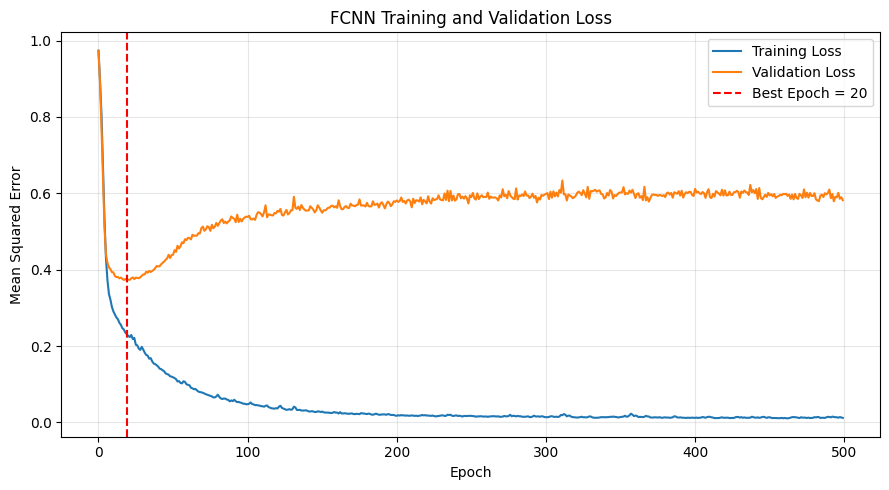

In [17]:
# Plot the initial training and validation losses.
plt.figure(figsize=(9, 5))

plt.plot(training_losses, label="Training Loss")
plt.plot(validation_losses, label="Validation Loss")

plt.axvline(
    best_epoch - 1, color="red", linestyle="--",
    label=f"Best Epoch = {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("FCNN Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
# Evaluate the initial model in actual dollar values.
model.eval()

with torch.no_grad():
    NN_predictions_scaled = model(X_test_tensor).numpy()

NN_predictions = Y_scaler.inverse_transform(
    NN_predictions_scaled
).ravel()

Y_test_actual = Y_test.to_numpy()

NN_mse = mean_squared_error(Y_test_actual, NN_predictions)
NN_rmse = np.sqrt(NN_mse)
NN_r2 = r2_score(Y_test_actual, NN_predictions)

print("FCNN Test Results")
print(f"MSE:  {NN_mse:,.2f}")
print(f"RMSE: ${NN_rmse:,.2f}")
print(f"R²:    {NN_r2:.6f}")

FCNN Test Results
MSE:  1,785,621,118,976.00
RMSE: $1,336,271.35
R²:    0.646731


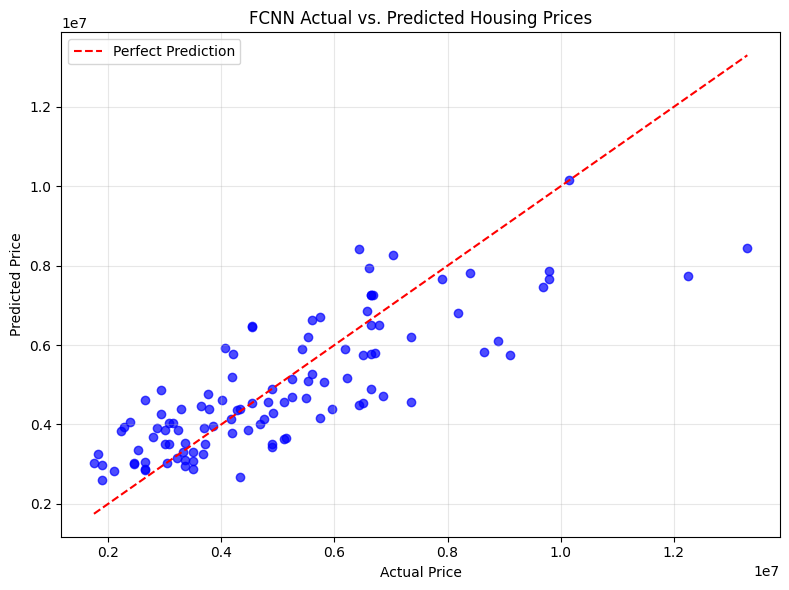

In [21]:
# Compare the initial predictions with the actual prices.
minimum_price = min(Y_test_actual.min(), NN_predictions.min())
maximum_price = max(Y_test_actual.max(), NN_predictions.max())

plt.figure(figsize=(8, 6))

plt.scatter(
    Y_test_actual, NN_predictions,
    color="blue", alpha=0.7
)

plt.plot(
    [minimum_price, maximum_price],
    [minimum_price, maximum_price],
    color="red", linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("FCNN Actual vs. Predicted Housing Prices")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Smaller regularized housing FCNN


In [22]:
# Define a smaller network with dropout regularization.
class RegularizedHousingFCNN(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 32),
            nn.ReLU(),
            nn.Dropout(0.10),

            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Dropout(0.10),

            nn.Linear(16, 1)
        )

    def forward(self, X):
        return self.network(X)

In [24]:
# Train the regularized model with early stopping.
regularized_model = RegularizedHousingFCNN(input_size)

regularized_optimizer = torch.optim.Adam(
    regularized_model.parameters(),
    lr=0.001,
    weight_decay=0.001
)

reg_training_losses = []
reg_validation_losses = []

reg_best_validation_loss = float("inf")
reg_best_model_state = None
reg_best_epoch = 0

patience = 40
epochs_without_improvement = 0

for epoch in range(500):
    regularized_model.train()
    total_training_loss = 0

    for batch_X, batch_Y in training_loader:
        predictions = regularized_model(batch_X)
        loss = criterion(predictions, batch_Y)

        regularized_optimizer.zero_grad()
        loss.backward()
        regularized_optimizer.step()

        total_training_loss += loss.item() * batch_X.size(0)

    training_loss = total_training_loss / len(training_dataset)

    regularized_model.eval()

    with torch.no_grad():
        validation_predictions = regularized_model(X_val_tensor)
        validation_loss = criterion(
            validation_predictions, Y_val_tensor
        ).item()

    reg_training_losses.append(training_loss)
    reg_validation_losses.append(validation_loss)

    if validation_loss < reg_best_validation_loss:
        reg_best_validation_loss = validation_loss
        reg_best_epoch = epoch + 1
        reg_best_model_state = copy.deepcopy(
            regularized_model.state_dict()
        )
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if (epoch + 1) % 25 == 0:
        print(
            f"Epoch {epoch + 1}, "
            f"Training Loss: {training_loss:.6f}, "
            f"Validation Loss: {validation_loss:.6f}"
        )

    if epochs_without_improvement >= patience:
        print(f"\nEarly stopping at epoch {epoch + 1}")
        break

regularized_model.load_state_dict(reg_best_model_state)

print("\nOriginal best validation loss:", best_validation_loss)
print("Regularized best validation loss:", reg_best_validation_loss)
print("Regularized best epoch:", reg_best_epoch)

Epoch 25, Training Loss: 0.306322, Validation Loss: 0.368921
Epoch 50, Training Loss: 0.269824, Validation Loss: 0.359393
Epoch 75, Training Loss: 0.236569, Validation Loss: 0.367974

Early stopping at epoch 99

Original best validation loss: 0.3722967803478241
Regularized best validation loss: 0.3582012951374054
Regularized best epoch: 59


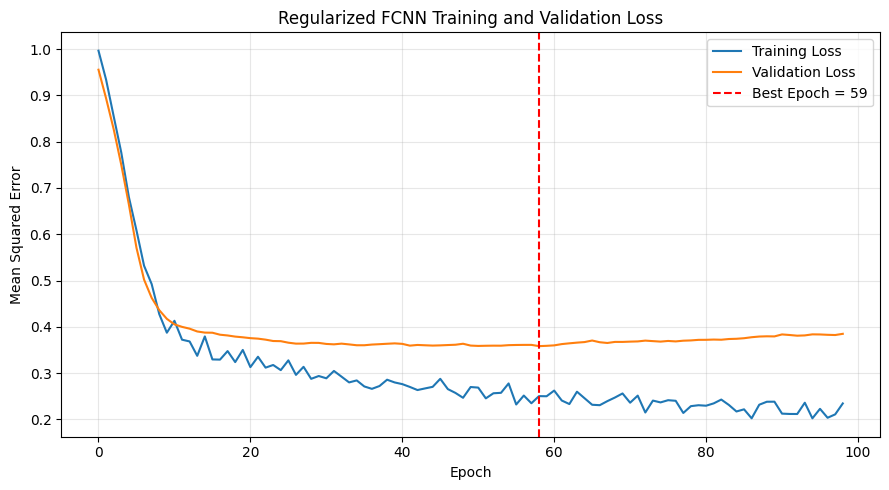

In [25]:
# Plot the regularized model's training and validation losses.
plt.figure(figsize=(9, 5))

plt.plot(reg_training_losses, label="Training Loss")
plt.plot(reg_validation_losses, label="Validation Loss")

plt.axvline(
    reg_best_epoch - 1, color="red", linestyle="--",
    label=f"Best Epoch = {reg_best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Regularized FCNN Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
# Evaluate the regularized model before final retraining.
final_model = regularized_model
final_model.eval()

with torch.no_grad():
    FCNN_predictions_scaled = final_model(
        X_test_tensor
    ).numpy()

FCNN_predictions = Y_scaler.inverse_transform(
    FCNN_predictions_scaled
).ravel()

FCNN_mse = mean_squared_error(
    Y_test_actual, FCNN_predictions
)

FCNN_rmse = np.sqrt(FCNN_mse)
FCNN_r2 = r2_score(Y_test_actual, FCNN_predictions)

print("Final Regularized FCNN Results")
print(f"MSE:  {FCNN_mse:,.2f}")
print(f"RMSE: ${FCNN_rmse:,.2f}")
print(f"R²:    {FCNN_r2:.6f}")

Final Regularized FCNN Results
MSE:  1,829,766,955,008.00
RMSE: $1,352,688.79
R²:    0.637998


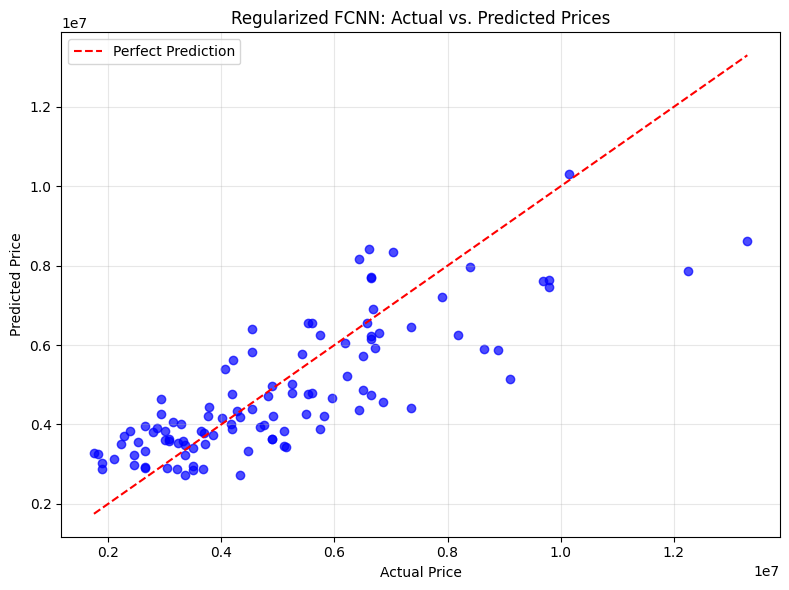

In [28]:
# Plot the regularized predictions from the validation-stage model.
minimum_price = min(
    Y_test_actual.min(), FCNN_predictions.min()
)

maximum_price = max(
    Y_test_actual.max(), FCNN_predictions.max()
)

plt.figure(figsize=(8, 6))

plt.scatter(
    Y_test_actual, FCNN_predictions,
    color="blue", alpha=0.7
)

plt.plot(
    [minimum_price, maximum_price],
    [minimum_price, maximum_price],
    color="red", linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Regularized FCNN: Actual vs. Predicted Prices")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Final housing model using the complete training set


In [29]:
# Refit preprocessing on the complete 80% training set.
final_preprocessor = ColumnTransformer([
    ("numerical", StandardScaler(), numerical_columns),
    ("categorical", OneHotEncoder(
        drop="first", handle_unknown="ignore",
        sparse_output=False
    ), categorical_columns)
])

X_final_train = final_preprocessor.fit_transform(X_train_full)
X_final_test = final_preprocessor.transform(X_test)

final_Y_scaler = StandardScaler()

Y_final_train_scaled = final_Y_scaler.fit_transform(
    Y_train_full.to_numpy().reshape(-1, 1)
).ravel()

print("Final training shape:", X_final_train.shape)
print("Final testing shape:", X_final_test.shape)

Final training shape: (436, 13)
Final testing shape: (109, 13)


In [30]:
# Create tensors and mini-batches for final housing training.
X_final_train_tensor = torch.tensor(
    X_final_train, dtype=torch.float32
)

Y_final_train_tensor = torch.tensor(
    Y_final_train_scaled, dtype=torch.float32
).reshape(-1, 1)

X_final_test_tensor = torch.tensor(
    X_final_test, dtype=torch.float32
)

final_dataset = TensorDataset(
    X_final_train_tensor, Y_final_train_tensor
)

final_loader = DataLoader(
    final_dataset, batch_size=32, shuffle=True
)

In [31]:
# Retrain the selected housing architecture for 59 epochs.
torch.manual_seed(42)

final_model = RegularizedHousingFCNN(
    X_final_train_tensor.shape[1]
)

final_optimizer = torch.optim.Adam(
    final_model.parameters(),
    lr=0.001,
    weight_decay=0.001
)

final_training_losses = []

for epoch in range(reg_best_epoch):
    final_model.train()
    total_loss = 0

    for batch_X, batch_Y in final_loader:
        predictions = final_model(batch_X)
        loss = criterion(predictions, batch_Y)

        final_optimizer.zero_grad()
        loss.backward()
        final_optimizer.step()

        total_loss += loss.item() * batch_X.size(0)

    final_loss = total_loss / len(final_dataset)
    final_training_losses.append(final_loss)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1}, "
            f"Training Loss: {final_loss:.6f}"
        )

Epoch 10, Training Loss: 0.375731
Epoch 20, Training Loss: 0.325047
Epoch 30, Training Loss: 0.289323
Epoch 40, Training Loss: 0.250168
Epoch 50, Training Loss: 0.278957


In [32]:
# Calculate the final FCNN housing test metrics.
final_model.eval()

with torch.no_grad():
    FCNN_predictions_scaled = final_model(
        X_final_test_tensor
    ).numpy()

FCNN_predictions = final_Y_scaler.inverse_transform(
    FCNN_predictions_scaled
).ravel()

Y_test_actual = Y_test.to_numpy()

FCNN_mse = mean_squared_error(
    Y_test_actual, FCNN_predictions
)

FCNN_rmse = np.sqrt(FCNN_mse)
FCNN_r2 = r2_score(Y_test_actual, FCNN_predictions)

print("\nFinal FCNN Test Results")
print(f"MSE:  {FCNN_mse:,.2f}")
print(f"RMSE: ${FCNN_rmse:,.2f}")
print(f"R²:    {FCNN_r2:.6f}")


Final FCNN Test Results
MSE:  1,667,220,766,720.00
RMSE: $1,291,209.03
R²:    0.670156


### Housing comparison with Linear Regression and SVR


In [33]:
# Train and evaluate the Linear Regression baseline.
LR_model = LinearRegression()
LR_model.fit(X_final_train, Y_train_full)

LR_predictions = LR_model.predict(X_final_test)

LR_mse = mean_squared_error(Y_test_actual, LR_predictions)
LR_rmse = np.sqrt(LR_mse)
LR_r2 = r2_score(Y_test_actual, LR_predictions)

print("Linear Regression Results")
print(f"MSE:  {LR_mse:,.2f}")
print(f"RMSE: ${LR_rmse:,.2f}")
print(f"R²:    {LR_r2:.6f}")

Linear Regression Results
MSE:  1,754,318,687,330.67
RMSE: $1,324,506.96
R²:    0.652924


In [35]:
# Tune SVR hyperparameters with five-fold cross-validation.
from sklearn.model_selection import GridSearchCV

SVR_parameters = {
    "kernel": ["linear", "rbf", "poly"],
    "C": [1, 10, 100],
    "epsilon": [0.01, 0.1, 0.2],
    "gamma": ["scale", "auto"]
}

SVR_search = GridSearchCV(
    SVR(),
    SVR_parameters,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

SVR_search.fit(X_final_train, Y_final_train_scaled)

best_SVR = SVR_search.best_estimator_

print("Best SVR parameters:", SVR_search.best_params_)

Best SVR parameters: {'C': 100, 'epsilon': 0.01, 'gamma': 'scale', 'kernel': 'linear'}


In [36]:
# Convert SVR predictions back to dollars and evaluate them.
SVR_predictions_scaled = best_SVR.predict(
    X_final_test
).reshape(-1, 1)

SVR_predictions = final_Y_scaler.inverse_transform(
    SVR_predictions_scaled
).ravel()

SVR_mse = mean_squared_error(Y_test_actual, SVR_predictions)
SVR_rmse = np.sqrt(SVR_mse)
SVR_r2 = r2_score(Y_test_actual, SVR_predictions)

print("\nSVR Results")
print(f"MSE:  {SVR_mse:,.2f}")
print(f"RMSE: ${SVR_rmse:,.2f}")
print(f"R²:    {SVR_r2:.6f}")


SVR Results
MSE:  1,904,828,428,945.08
RMSE: $1,380,155.22
R²:    0.623147


In [37]:
# Place the three housing models in one comparison table.
comparison_table = pd.DataFrame({
    "Model": ["Linear Regression", "SVR", "FCNN"],
    "MSE": [LR_mse, SVR_mse, FCNN_mse],
    "RMSE": [LR_rmse, SVR_rmse, FCNN_rmse],
    "R²": [LR_r2, SVR_r2, FCNN_r2]
})

comparison_table = comparison_table.sort_values(
    "RMSE"
).reset_index(drop=True)

comparison_table.style.format({
    "MSE": "{:,.2f}",
    "RMSE": "${:,.2f}",
    "R²": "{:.6f}"
})

,Model,MSE,RMSE,R²
0,FCNN,"1,667,220,766,720.00","$1,291,209.03",0.670156
1,Linear Regression,"1,754,318,687,330.67","$1,324,506.96",0.652924
2,SVR,"1,904,828,428,945.08","$1,380,155.22",0.623147


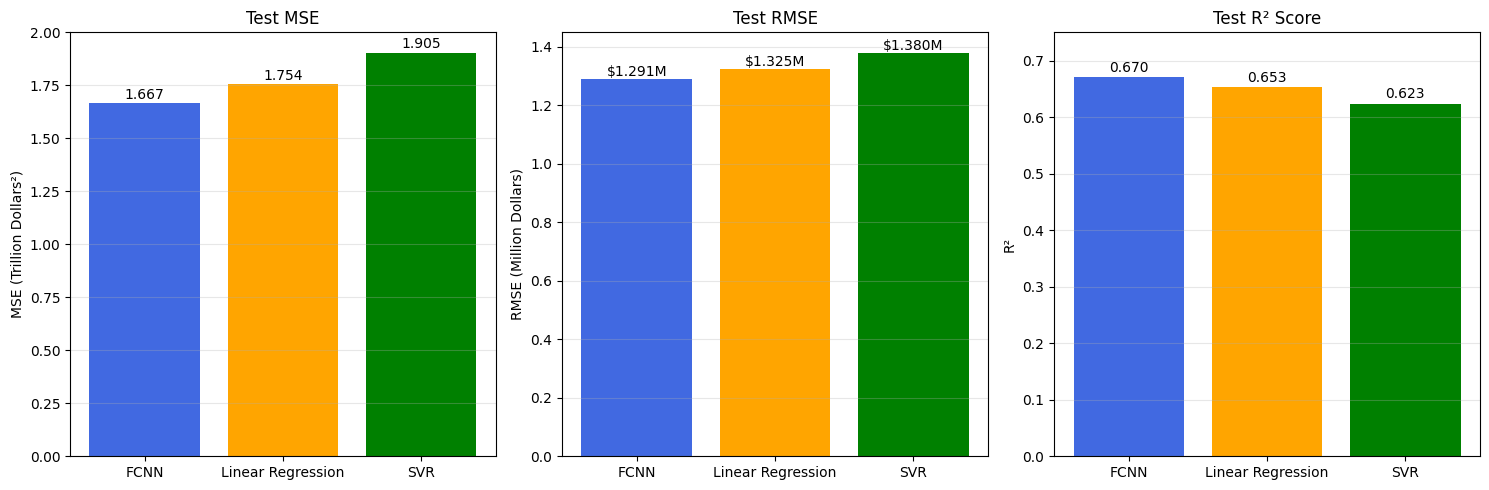

In [38]:
# Plot the housing model comparison.
models = comparison_table["Model"]
mse_values = comparison_table["MSE"] / 1e12
rmse_values = comparison_table["RMSE"] / 1e6
r2_values = comparison_table["R²"]

colors = ["royalblue", "orange", "green"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

bars_1 = axes[0].bar(models, mse_values, color=colors)
axes[0].set_title("Test MSE")
axes[0].set_ylabel("MSE (Trillion Dollars²)")
axes[0].grid(axis="y", alpha=0.3)

bars_2 = axes[1].bar(models, rmse_values, color=colors)
axes[1].set_title("Test RMSE")
axes[1].set_ylabel("RMSE (Million Dollars)")
axes[1].grid(axis="y", alpha=0.3)

bars_3 = axes[2].bar(models, r2_values, color=colors)
axes[2].set_title("Test R² Score")
axes[2].set_ylabel("R²")
axes[2].set_ylim(0, 0.75)
axes[2].grid(axis="y", alpha=0.3)

for bar, value in zip(bars_1, mse_values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{value:.3f}", ha="center"
    )

for bar, value in zip(bars_2, rmse_values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"${value:.3f}M", ha="center"
    )

for bar, value in zip(bars_3, r2_values):
    axes[2].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{value:.3f}", ha="center"
    )

plt.tight_layout()
plt.show()

## Problem 2 Breast Cancer Classification

Malignant cancer is encoded as the positive class so precision, recall, and F1 describe malignant detection.


In [39]:
# Import classification metrics and baseline classifiers.
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

In [42]:
# Load and inspect the breast cancer dataset.
file_path = "/content/drive/MyDrive/Dataset/Cancer.csv"
cancer = pd.read_csv(file_path)

print("Dataset shape:", cancer.shape)
print("\nColumns:")
print(cancer.columns.tolist())

print("\nMissing values:")
print(cancer.isnull().sum())

print("\nDiagnosis values:")
print(cancer["diagnosis"].value_counts())

Dataset shape: (569, 33)

Columns:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']

Missing values:
id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean     

In [43]:
# Remove identifiers and encode malignant cancer as class 1.
cancer = cancer.drop(
    columns=["id", "Unnamed: 32"],
    errors="ignore"
)

X_cancer = cancer.drop("diagnosis", axis=1)

Y_cancer = cancer["diagnosis"].map({
    "M": 1,
    "B": 0
})

print("X shape:", X_cancer.shape)
print("Y shape:", Y_cancer.shape)

print("\nEncoded target counts:")
print(Y_cancer.value_counts())

print("\nMissing encoded targets:")
print(Y_cancer.isnull().sum())

X shape: (569, 30)
Y shape: (569,)

Encoded target counts:
diagnosis
0    357
1    212
Name: count, dtype: int64

Missing encoded targets:
0


### Stratified split and feature standardization


In [44]:
# Make stratified training, validation, and testing splits.
X_cancer_train_full, X_cancer_test, Y_cancer_train_full, Y_cancer_test = (
    train_test_split(
        X_cancer, Y_cancer,
        test_size=0.20,
        random_state=42,
        stratify=Y_cancer
    )
)

X_cancer_train, X_cancer_val, Y_cancer_train, Y_cancer_val = (
    train_test_split(
        X_cancer_train_full,
        Y_cancer_train_full,
        test_size=0.20,
        random_state=42,
        stratify=Y_cancer_train_full
    )
)

print("Training:", X_cancer_train.shape)
print("Validation:", X_cancer_val.shape)
print("Testing:", X_cancer_test.shape)

print("\nTraining labels:")
print(Y_cancer_train.value_counts())

print("\nValidation labels:")
print(Y_cancer_val.value_counts())

print("\nTesting labels:")
print(Y_cancer_test.value_counts())

Training: (364, 30)
Validation: (91, 30)
Testing: (114, 30)

Training labels:
diagnosis
0    228
1    136
Name: count, dtype: int64

Validation labels:
diagnosis
0    57
1    34
Name: count, dtype: int64

Testing labels:
diagnosis
0    72
1    42
Name: count, dtype: int64


In [45]:
# Standardize all 30 cancer input features.
cancer_scaler = StandardScaler()

X_cancer_train_scaled = cancer_scaler.fit_transform(
    X_cancer_train
)

X_cancer_val_scaled = cancer_scaler.transform(
    X_cancer_val
)

X_cancer_test_scaled = cancer_scaler.transform(
    X_cancer_test
)

print("Scaled training:", X_cancer_train_scaled.shape)
print("Scaled validation:", X_cancer_val_scaled.shape)
print("Scaled testing:", X_cancer_test_scaled.shape)

Scaled training: (364, 30)
Scaled validation: (91, 30)
Scaled testing: (114, 30)


In [46]:
# Convert the cancer data into tensors and mini-batches.
X_cancer_train_tensor = torch.tensor(
    X_cancer_train_scaled, dtype=torch.float32
)

X_cancer_val_tensor = torch.tensor(
    X_cancer_val_scaled, dtype=torch.float32
)

X_cancer_test_tensor = torch.tensor(
    X_cancer_test_scaled, dtype=torch.float32
)

Y_cancer_train_tensor = torch.tensor(
    Y_cancer_train.to_numpy(), dtype=torch.float32
).reshape(-1, 1)

Y_cancer_val_tensor = torch.tensor(
    Y_cancer_val.to_numpy(), dtype=torch.float32
).reshape(-1, 1)

Y_cancer_test_tensor = torch.tensor(
    Y_cancer_test.to_numpy(), dtype=torch.float32
).reshape(-1, 1)

cancer_training_dataset = TensorDataset(
    X_cancer_train_tensor,
    Y_cancer_train_tensor
)

cancer_training_loader = DataLoader(
    cancer_training_dataset,
    batch_size=32,
    shuffle=True
)

print("Training tensor:", X_cancer_train_tensor.shape)
print("Target tensor:", Y_cancer_train_tensor.shape)

Training tensor: torch.Size([364, 30])
Target tensor: torch.Size([364, 1])


### Cancer FCNN development and training


In [47]:
# Define the cancer classifier with two hidden layers.
class CancerFCNN(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 32),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.Linear(16, 1)
        )

    def forward(self, X):
        return self.network(X)

In [48]:
# Set the classification batch size.
cancer_batch_size = 32

cancer_training_dataset = TensorDataset(
    X_cancer_train_tensor,
    Y_cancer_train_tensor
)

cancer_training_loader = DataLoader(
    cancer_training_dataset,
    batch_size=cancer_batch_size,
    shuffle=True
)

In [49]:
# Create the classifier, binary loss, and Adam optimizer.
import copy

torch.manual_seed(42)

cancer_model = CancerFCNN(
    X_cancer_train_tensor.shape[1]
)

cancer_criterion = nn.BCEWithLogitsLoss()

cancer_optimizer = torch.optim.Adam(
    cancer_model.parameters(),
    lr=0.001,
    weight_decay=0.001
)

print(cancer_model)

CancerFCNN(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=16, out_features=1, bias=True)
  )
)


In [50]:
# Train the classifier while tracking loss and accuracy.
cancer_epochs = 300
cancer_patience = 40

cancer_training_losses = []
cancer_validation_losses = []
cancer_training_accuracies = []
cancer_validation_accuracies = []

cancer_best_validation_loss = float("inf")
cancer_best_model_state = None
cancer_best_epoch = 0
cancer_epochs_without_improvement = 0

for epoch in range(cancer_epochs):
    cancer_model.train()

    total_training_loss = 0
    correct_training = 0
    total_training = 0

    for batch_X, batch_Y in cancer_training_loader:
        logits = cancer_model(batch_X)
        loss = cancer_criterion(logits, batch_Y)

        cancer_optimizer.zero_grad()
        loss.backward()
        cancer_optimizer.step()

        total_training_loss += loss.item() * batch_X.size(0)

        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= 0.5).float()

        correct_training += (
            predictions == batch_Y
        ).sum().item()

        total_training += batch_Y.size(0)

    training_loss = (
        total_training_loss /
        len(cancer_training_dataset)
    )

    training_accuracy = (
        correct_training / total_training
    )

    cancer_model.eval()

    with torch.no_grad():
        validation_logits = cancer_model(
            X_cancer_val_tensor
        )

        validation_loss = cancer_criterion(
            validation_logits,
            Y_cancer_val_tensor
        ).item()

        validation_probabilities = torch.sigmoid(
            validation_logits
        )

        validation_predictions = (
            validation_probabilities >= 0.5
        ).float()

        validation_accuracy = (
            validation_predictions ==
            Y_cancer_val_tensor
        ).float().mean().item()

    cancer_training_losses.append(training_loss)
    cancer_validation_losses.append(validation_loss)

    cancer_training_accuracies.append(training_accuracy)
    cancer_validation_accuracies.append(validation_accuracy)

    if validation_loss < cancer_best_validation_loss:
        cancer_best_validation_loss = validation_loss
        cancer_best_epoch = epoch + 1

        cancer_best_model_state = copy.deepcopy(
            cancer_model.state_dict()
        )

        cancer_epochs_without_improvement = 0
    else:
        cancer_epochs_without_improvement += 1

    if (epoch + 1) % 25 == 0:
        print(
            f"Epoch {epoch + 1}, "
            f"Train Loss: {training_loss:.6f}, "
            f"Val Loss: {validation_loss:.6f}, "
            f"Train Acc: {training_accuracy:.4f}, "
            f"Val Acc: {validation_accuracy:.4f}"
        )

    if cancer_epochs_without_improvement >= cancer_patience:
        print(f"\nEarly stopping at epoch {epoch + 1}")
        break

cancer_model.load_state_dict(cancer_best_model_state)

print("\nBest epoch:", cancer_best_epoch)
print("Best validation loss:", cancer_best_validation_loss)

Epoch 25, Train Loss: 0.059144, Val Loss: 0.075826, Train Acc: 0.9835, Val Acc: 0.9780
Epoch 50, Train Loss: 0.040157, Val Loss: 0.073842, Train Acc: 0.9863, Val Acc: 0.9780
Epoch 75, Train Loss: 0.025194, Val Loss: 0.073777, Train Acc: 0.9945, Val Acc: 0.9780
Epoch 100, Train Loss: 0.015683, Val Loss: 0.079512, Train Acc: 0.9945, Val Acc: 0.9780

Early stopping at epoch 101

Best epoch: 61
Best validation loss: 0.07294850051403046


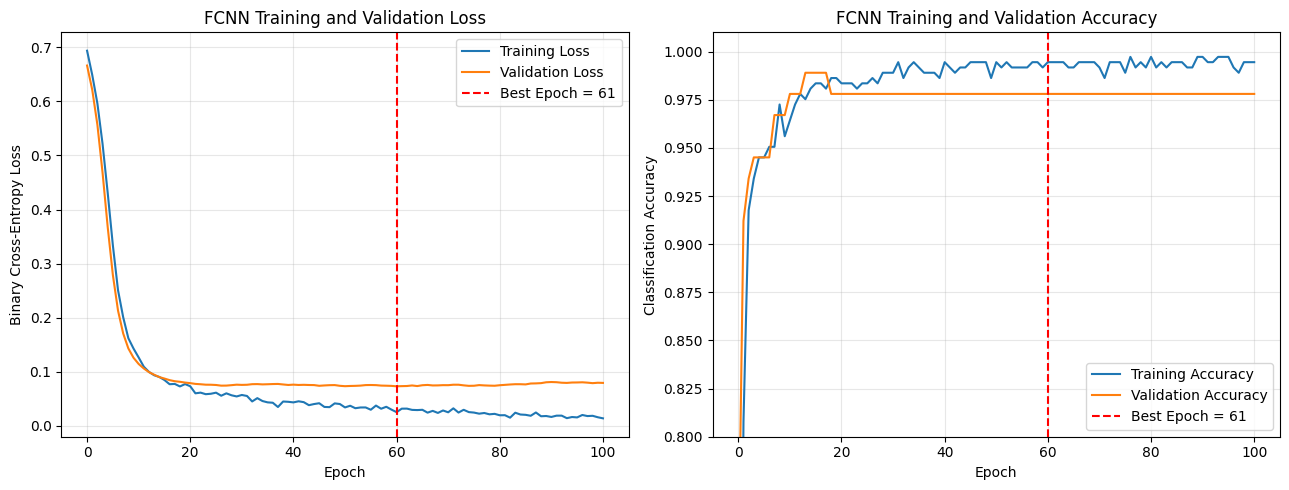

In [51]:
# Plot classification loss and accuracy over the epochs.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    cancer_training_losses,
    label="Training Loss"
)

axes[0].plot(
    cancer_validation_losses,
    label="Validation Loss"
)

axes[0].axvline(
    cancer_best_epoch - 1,
    color="red", linestyle="--",
    label=f"Best Epoch = {cancer_best_epoch}"
)

axes[0].set_title("FCNN Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    cancer_training_accuracies,
    label="Training Accuracy"
)

axes[1].plot(
    cancer_validation_accuracies,
    label="Validation Accuracy"
)

axes[1].axvline(
    cancer_best_epoch - 1,
    color="red", linestyle="--",
    label=f"Best Epoch = {cancer_best_epoch}"
)

axes[1].set_title("FCNN Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Classification Accuracy")
axes[1].set_ylim(0.80, 1.01)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Final cancer model using the complete training set


In [52]:
# Refit the scaler on the complete 80% cancer training set.
cancer_final_scaler = StandardScaler()

X_cancer_final_train = cancer_final_scaler.fit_transform(
    X_cancer_train_full
)

X_cancer_final_test = cancer_final_scaler.transform(
    X_cancer_test
)

X_cancer_final_train_tensor = torch.tensor(
    X_cancer_final_train, dtype=torch.float32
)

X_cancer_final_test_tensor = torch.tensor(
    X_cancer_final_test, dtype=torch.float32
)

Y_cancer_final_train_tensor = torch.tensor(
    Y_cancer_train_full.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

cancer_final_dataset = TensorDataset(
    X_cancer_final_train_tensor,
    Y_cancer_final_train_tensor
)

cancer_final_loader = DataLoader(
    cancer_final_dataset,
    batch_size=32,
    shuffle=True
)

print("Final training:", X_cancer_final_train_tensor.shape)
print("Final testing:", X_cancer_final_test_tensor.shape)

Final training: torch.Size([455, 30])
Final testing: torch.Size([114, 30])


In [53]:
# Retrain the selected classifier for 61 epochs.
torch.manual_seed(42)

cancer_final_model = CancerFCNN(
    X_cancer_final_train_tensor.shape[1]
)

cancer_final_optimizer = torch.optim.Adam(
    cancer_final_model.parameters(),
    lr=0.001,
    weight_decay=0.001
)

for epoch in range(cancer_best_epoch):
    cancer_final_model.train()
    total_loss = 0

    for batch_X, batch_Y in cancer_final_loader:
        logits = cancer_final_model(batch_X)
        loss = cancer_criterion(logits, batch_Y)

        cancer_final_optimizer.zero_grad()
        loss.backward()
        cancer_final_optimizer.step()

        total_loss += loss.item() * batch_X.size(0)

    final_training_loss = (
        total_loss / len(cancer_final_dataset)
    )

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1}, "
            f"Training Loss: {final_training_loss:.6f}"
        )

Epoch 10, Training Loss: 0.110310
Epoch 20, Training Loss: 0.062029
Epoch 30, Training Loss: 0.045924
Epoch 40, Training Loss: 0.040379
Epoch 50, Training Loss: 0.030626
Epoch 60, Training Loss: 0.028175


In [54]:
# Calculate FCNN accuracy, precision, recall, and F1 score.
cancer_final_model.eval()

with torch.no_grad():
    cancer_test_logits = cancer_final_model(
        X_cancer_final_test_tensor
    )

    cancer_test_probabilities = torch.sigmoid(
        cancer_test_logits
    ).numpy().ravel()

cancer_FCNN_predictions = (
    cancer_test_probabilities >= 0.5
).astype(int)

cancer_FCNN_accuracy = accuracy_score(
    Y_cancer_test, cancer_FCNN_predictions
)

cancer_FCNN_precision = precision_score(
    Y_cancer_test, cancer_FCNN_predictions
)

cancer_FCNN_recall = recall_score(
    Y_cancer_test, cancer_FCNN_predictions
)

cancer_FCNN_f1 = f1_score(
    Y_cancer_test, cancer_FCNN_predictions
)

print("Final Cancer FCNN Results")
print(f"Accuracy:  {cancer_FCNN_accuracy:.4f}")
print(f"Precision: {cancer_FCNN_precision:.4f}")
print(f"Recall:    {cancer_FCNN_recall:.4f}")
print(f"F1 Score:  {cancer_FCNN_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    Y_cancer_test,
    cancer_FCNN_predictions,
    target_names=["Benign", "Malignant"],
    digits=4
))

Final Cancer FCNN Results
Accuracy:  0.9737
Precision: 1.0000
Recall:    0.9286
F1 Score:  0.9630

Classification Report:
              precision    recall  f1-score   support

      Benign     0.9600    1.0000    0.9796        72
   Malignant     1.0000    0.9286    0.9630        42

    accuracy                         0.9737       114
   macro avg     0.9800    0.9643    0.9713       114
weighted avg     0.9747    0.9737    0.9735       114



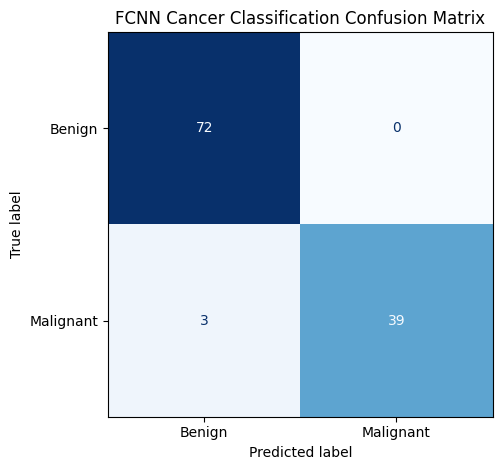

In [55]:
# Plot the FCNN confusion matrix.
ConfusionMatrixDisplay.from_predictions(
    Y_cancer_test,
    cancer_FCNN_predictions,
    display_labels=["Benign", "Malignant"],
    cmap="Blues",
    colorbar=False
)

plt.title("FCNN Cancer Classification Confusion Matrix")
plt.tight_layout()
plt.show()

### Cancer comparison with Logistic Regression and SVM


In [56]:
# Train and evaluate the Logistic Regression baseline.
cancer_LR_model = LogisticRegression(
    max_iter=5000,
    random_state=42
)

cancer_LR_model.fit(
    X_cancer_final_train,
    Y_cancer_train_full
)

cancer_LR_predictions = cancer_LR_model.predict(
    X_cancer_final_test
)

cancer_LR_accuracy = accuracy_score(
    Y_cancer_test, cancer_LR_predictions
)

cancer_LR_precision = precision_score(
    Y_cancer_test, cancer_LR_predictions
)

cancer_LR_recall = recall_score(
    Y_cancer_test, cancer_LR_predictions
)

cancer_LR_f1 = f1_score(
    Y_cancer_test, cancer_LR_predictions
)

print("Logistic Regression Results")
print(f"Accuracy:  {cancer_LR_accuracy:.4f}")
print(f"Precision: {cancer_LR_precision:.4f}")
print(f"Recall:    {cancer_LR_recall:.4f}")
print(f"F1 Score:  {cancer_LR_f1:.4f}")

Logistic Regression Results
Accuracy:  0.9649
Precision: 0.9750
Recall:    0.9286
F1 Score:  0.9512


In [57]:
# Tune the SVM kernels and hyperparameters using F1 score.
from sklearn.model_selection import GridSearchCV
cancer_SVM_parameters = {
    "kernel": ["linear", "rbf", "poly"],
    "C": [0.1, 1, 10, 100],
    "gamma": ["scale", "auto", 0.01, 0.1]
}

cancer_SVM_search = GridSearchCV(
    SVC(),
    cancer_SVM_parameters,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

cancer_SVM_search.fit(
    X_cancer_final_train,
    Y_cancer_train_full
)

cancer_SVM_model = cancer_SVM_search.best_estimator_

print("Best SVM parameters:")
print(cancer_SVM_search.best_params_)

Best SVM parameters:
{'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}


In [58]:
# Evaluate the selected SVM on the test set.
cancer_SVM_predictions = cancer_SVM_model.predict(
    X_cancer_final_test
)

cancer_SVM_accuracy = accuracy_score(
    Y_cancer_test, cancer_SVM_predictions
)

cancer_SVM_precision = precision_score(
    Y_cancer_test, cancer_SVM_predictions
)

cancer_SVM_recall = recall_score(
    Y_cancer_test, cancer_SVM_predictions
)

cancer_SVM_f1 = f1_score(
    Y_cancer_test, cancer_SVM_predictions
)

print("\nSVM Results")
print(f"Accuracy:  {cancer_SVM_accuracy:.4f}")
print(f"Precision: {cancer_SVM_precision:.4f}")
print(f"Recall:    {cancer_SVM_recall:.4f}")
print(f"F1 Score:  {cancer_SVM_f1:.4f}")


SVM Results
Accuracy:  0.9737
Precision: 1.0000
Recall:    0.9286
F1 Score:  0.9630


In [59]:
# Build the cancer classification comparison table.
cancer_comparison = pd.DataFrame({
    "Model": [
        "FCNN",
        "Logistic Regression",
        "SVM"
    ],
    "Accuracy": [
        cancer_FCNN_accuracy,
        cancer_LR_accuracy,
        cancer_SVM_accuracy
    ],
    "Precision": [
        cancer_FCNN_precision,
        cancer_LR_precision,
        cancer_SVM_precision
    ],
    "Recall": [
        cancer_FCNN_recall,
        cancer_LR_recall,
        cancer_SVM_recall
    ],
    "F1 Score": [
        cancer_FCNN_f1,
        cancer_LR_f1,
        cancer_SVM_f1
    ]
})

cancer_comparison.style.format({
    "Accuracy": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1 Score": "{:.4f}"
})

,Model,Accuracy,Precision,Recall,F1 Score
0,FCNN,0.9737,1.0000,0.9286,0.9630
1,Logistic Regression,0.9649,0.9750,0.9286,0.9512
2,SVM,0.9737,1.0000,0.9286,0.9630


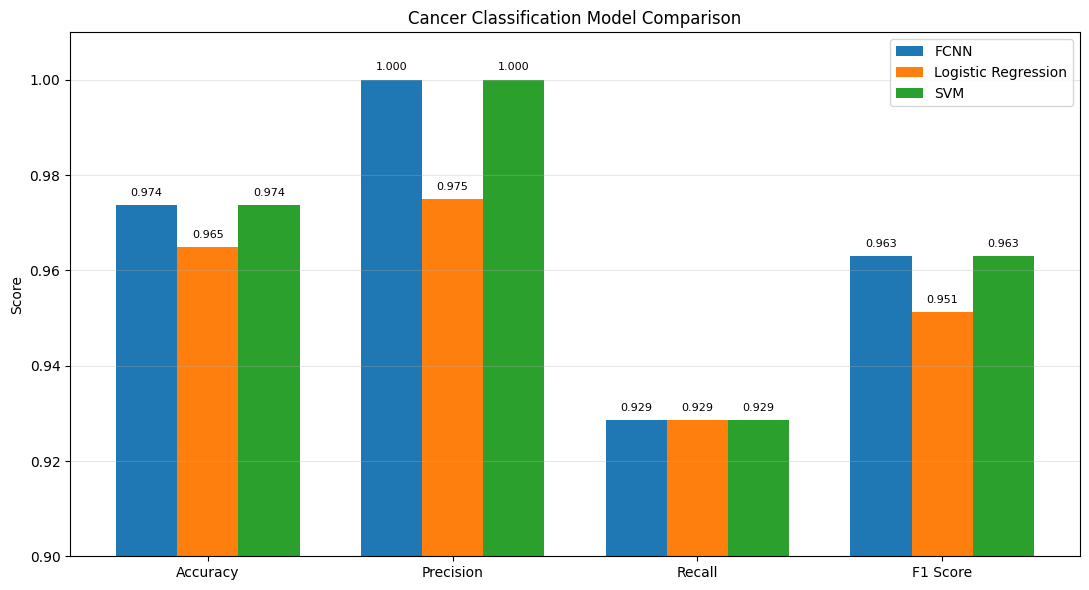

In [60]:
# Plot the final classification model comparison.
comparison_metrics = [
    "Accuracy", "Precision",
    "Recall", "F1 Score"
]

X_positions = np.arange(len(comparison_metrics))
bar_width = 0.25

plt.figure(figsize=(11, 6))

FCNN_bars = plt.bar(
    X_positions - bar_width,
    cancer_comparison.loc[0, comparison_metrics],
    width=bar_width,
    label="FCNN"
)

LR_bars = plt.bar(
    X_positions,
    cancer_comparison.loc[1, comparison_metrics],
    width=bar_width,
    label="Logistic Regression"
)

SVM_bars = plt.bar(
    X_positions + bar_width,
    cancer_comparison.loc[2, comparison_metrics],
    width=bar_width,
    label="SVM"
)

plt.xticks(X_positions, comparison_metrics)
plt.ylabel("Score")
plt.title("Cancer Classification Model Comparison")
plt.ylim(0.90, 1.01)
plt.legend()
plt.grid(axis="y", alpha=0.3)

for bars in [FCNN_bars, LR_bars, SVM_bars]:
    for bar in bars:
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.002,
            f"{bar.get_height():.3f}",
            ha="center",
            fontsize=8
        )

plt.tight_layout()
plt.show()